# (1) Business Understanding

- **Tujuan** : Memberikan rekomendasi berdasarkan hasil analisis performa penjualan dan operasional bisnis E-Commerce.

- **Permasalahan** : Bisnis E-Commerce memiliki berbagai transaksi penjualan, tetapi belum mengetahui secara mendalam bagaimana tren total pembayaran, kategori produk yang paling banyak dipesan, wilayah dengan nilai transaksi terbesar, serta pola diskon, metode pembayaran, dan pembatalan pesanan.

- **Objective Task** :
  - Bagaimana tren total pembayaran E-Commerce berdasarkan periode transaksi?
  - Kategori produk apa yang memiliki jumlah pesanan terbanyak?
  - Wilayah atau provinsi mana yang menghasilkan nilai transaksi terbesar?
  - Bagaimana pola diskon, metode pembayaran, dan pembatalan pesanan?
  - Insight dan rekomendasi bisnis

# (2) Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests


sns.set()

# (3) Import Dataset

In [2]:
# GitHub API URL
api_url = "https://api.github.com/repos/BakiTacos/Indonesia-Ecommerce-Sales-Shipping-Data-2023-2025/contents/RAW_PUBLIC"

# Mengambil daftar file
response = requests.get(api_url)
response.raise_for_status()

# Memfilter file Excel
files = [
    item for item in response.json()
    if item["name"].endswith(".xlsx")
]

print("Total Dataset:", len(files))

Total Dataset: 24


In [3]:
# Membaca seluruh file Excel dari GitHub
dataframes = {}

for file in files:
    file_name = file["name"]
    file_url = file["download_url"]

    dataframes[file_name] = pd.read_excel(file_url)

print("Berhasil membaca:", len(dataframes), "file")

Berhasil membaca: 24 file


In [4]:
# Menampilkan lima baris pertama dari salah satu dataset
df = list(dataframes.values())[0]

# Menampilkan lima baris pertama dataset
df.head()

,order_id,product_category,Status Pesanan,Alasan Pembatalan,Opsi Pengiriman,Waktu Pesanan Dibuat,Metode Pembayaran,Jumlah,Returned quantity,Total Diskon,Total Berat,Ongkos Kirim Dibayar oleh Pembeli,Estimasi Potongan Biaya Pengiriman,Total Pembayaran,Perkiraan Ongkos Kirim,Kota/Kabupaten,Provinsi
0,ORD_0000001,Celengan,Selesai,NaN,Reguler (Cashless)-SPX Standard,2024-04-01 00:15,Saldo ShopeePay,1,0,0,1000 gr,0.0,10.0,38.300,10.0,KOTA SERANG,BANTEN
1,ORD_0000001,Celengan,Selesai,NaN,Reguler (Cashless)-SPX Standard,2024-04-01 00:15,Saldo ShopeePay,1,0,0,1000 gr,0.0,10.0,38.300,10.0,KOTA SERANG,BANTEN
2,ORD_0000002,Celengan,Selesai,NaN,Hemat Kargo-SPX Hemat,2024-04-01 01:47,COD (Bayar di Tempat),1,0,0,500 gr,0.0,14.5,18.576,14.5,KOTA SEMARANG,JAWA TENGAH
3,ORD_0000003,Celengan,Selesai,NaN,Hemat Kargo-SPX Hemat,2024-04-01 04:25,SeaBank Bayar Instan,1,0,0,500 gr,0.0,8.0,7.069,8.0,KAB. BOGOR,JAWA BARAT
4,ORD_0000004,Mangkok Sambal / Saus,Selesai,NaN,Hemat Kargo-SPX Hemat,2024-04-01 04:41,COD (Bayar di Tempat),2,0,0,400 gr,0.0,20.0,32.200,20.0,KOTA JAMBI,JAMBI


## (3.1) Preview Dataset
Melakukan micro analysis pada tahap preview dataset untuk memahami struktur dan karakteristik awal dari 24 dataset yang digunakan. Pemeriksaan dilakukan dengan membandingkan jumlah baris, jumlah kolom, serta nama kolom pada setiap dataset guna memastikan konsistensi data sebelum dilakukan penggabungan dan analisis lebih lanjut.

In [5]:
# Memeriksa struktur setiap dataset

for file_name, data in dataframes.items():

    print("\nDataset:", file_name)
    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())


Dataset: AprilSales2024_public.xlsx
Shape: (664, 17)
Columns: ['order_id', 'product_category', 'Status Pesanan', 'Alasan Pembatalan', 'Opsi Pengiriman', 'Waktu Pesanan Dibuat', 'Metode Pembayaran', 'Jumlah', 'Returned quantity', 'Total Diskon', 'Total Berat', 'Ongkos Kirim Dibayar oleh Pembeli', 'Estimasi Potongan Biaya Pengiriman', 'Total Pembayaran', 'Perkiraan Ongkos Kirim', 'Kota/Kabupaten', 'Provinsi']

Dataset: AprilSales2025_public.xlsx
Shape: (1041, 17)
Columns: ['order_id', 'product_category', 'Status Pesanan', 'Alasan Pembatalan', 'Opsi Pengiriman', 'Waktu Pesanan Dibuat', 'Metode Pembayaran', 'Jumlah', 'Returned quantity', 'Total Diskon', 'Total Berat', 'Ongkos Kirim Dibayar oleh Pembeli', 'Estimasi Potongan Biaya Pengiriman', 'Total Pembayaran', 'Perkiraan Ongkos Kirim', 'Kota/Kabupaten', 'Provinsi']

Dataset: AugustSales2024_public.xlsx
Shape: (1646, 17)
Columns: ['order_id', 'product_category', 'Status Pesanan', 'Alasan Pembatalan', 'Opsi Pengiriman', 'Waktu Pesanan Dibu

In [6]:
# Membandingkan struktur kolom setiap dataset

reference_columns = list(dataframes.values())[0].columns

for file_name, data in dataframes.items():

    if list(data.columns) != list(reference_columns):

        print("\nDataset:", file_name)
        print("Jumlah Kolom:", len(data.columns))

        print("Kolom Tambahan:",
              set(data.columns) - set(reference_columns))

        print("Kolom Hilang:",
              set(reference_columns) - set(data.columns))


Dataset: DecemberSales2024_public.xlsx
Jumlah Kolom: 17
Kolom Tambahan: {'Waktu Pengiriman Diatur'}
Kolom Hilang: {'Waktu Pesanan Dibuat'}

Dataset: JulySales2025_public.xlsx
Jumlah Kolom: 17
Kolom Tambahan: {'Waktu Pengiriman Diatur'}
Kolom Hilang: {'Waktu Pesanan Dibuat'}

Dataset: SeptemberSales2024_public.xlsx
Jumlah Kolom: 49
Kolom Tambahan: {'SKU Induk', 'Voucher Ditanggung Penjual', 'Harga Setelah Diskon', 'No. Telepon', 'Paket Diskon (Diskon dari Penjual)', 'Diskon Dari Penjual', 'Total Harga Produk', 'Diskon Kartu Kredit', 'Nama Penerima', 'Waktu Pembayaran Dilakukan', 'Catatan', 'Waktu Pengiriman Diatur', 'Berat Produk', 'Paket Diskon (Diskon dari Shopee)', 'Potongan Koin Shopee', 'Username (Pembeli)', 'Nama Variasi', 'Diskon Dari Shopee', 'Status Pembatalan/ Pengembalian', 'Catatan dari Pembeli', 'Waktu Pesanan Selesai', 'Voucher Ditanggung Shopee', 'Nomor Referensi SKU', 'Harga Awal', 'Pesanan Harus Dikirimkan Sebelum (Menghindari keterlambatan)', 'Alamat Pengiriman', 'Ant

**Hasil Preview Dataset:**

Berdasarkan pemeriksaan terhadap 24 dataset, ditemukan tiga file dengan struktur kolom yang berbeda. Dataset December 2024 dan July 2025 memiliki perbedaan nama kolom pada informasi waktu, sedangkan dataset September 2024 memiliki 49 kolom dengan informasi tambahan terkait produk, pembeli, diskon, dan pengiriman. Perbedaan struktur tersebut perlu diperiksa lebih lanjut untuk menentukan penyesuaian data sebelum proses penggabungan dilakukan.

## (3.2) Additional Dataset Inspection

Penjelasan:

Melakukan pemeriksaan lebih lanjut terhadap dataset September 2024 yang memiliki jumlah kolom lebih banyak dibandingkan dataset lainnya. Pemeriksaan bertujuan mengidentifikasi informasi tambahan dan menentukan relevansinya terhadap kebutuhan analisis.

In [7]:
# Menampilkan seluruh kolom dataset September 2024

df_september = dataframes['SeptemberSales2024_public.xlsx']

for i, column in enumerate(df_september.columns, 1):
    print(f"{i}. {column}")

1. order_id
2. product_category
3. Status Pesanan
4. Alasan Pembatalan
5. Status Pembatalan/ Pengembalian
6. No. Resi
7. Opsi Pengiriman
8. Antar ke counter/ pick-up
9. Pesanan Harus Dikirimkan Sebelum (Menghindari keterlambatan)
10. Waktu Pengiriman Diatur
11. Waktu Pesanan Dibuat
12. Waktu Pembayaran Dilakukan
13. Metode Pembayaran
14. SKU Induk
15. Nomor Referensi SKU
16. Nama Variasi
17. Harga Awal
18. Harga Setelah Diskon
19. Jumlah
20. Returned quantity
21. Total Harga Produk
22. Total Diskon
23. Diskon Dari Penjual
24. Diskon Dari Shopee
25. Berat Produk
26. Jumlah Produk di Pesan
27. Total Berat
28. Voucher Ditanggung Penjual
29. Cashback Koin
30. Voucher Ditanggung Shopee
31. Paket Diskon
32. Paket Diskon (Diskon dari Shopee)
33. Paket Diskon (Diskon dari Penjual)
34. Potongan Koin Shopee
35. Diskon Kartu Kredit
36. Ongkos Kirim Dibayar oleh Pembeli
37. Estimasi Potongan Biaya Pengiriman
38. Ongkos Kirim Pengembalian Barang
39. Total Pembayaran
40. Perkiraan Ongkos Kirim
41. C

**Hasil Pemeriksaan Dataset September 2024:**

Berdasarkan pemeriksaan lebih lanjut, dataset September 2024 memiliki 49 kolom, sedangkan mayoritas dataset lainnya memiliki 17 kolom. Kolom tambahan mencakup informasi detail produk, harga, diskon, pembayaran, dan pengiriman. Selain itu, terdapat beberapa kolom yang mengandung informasi pribadi pelanggan sehingga tidak digunakan dalam analisis publik. Untuk menjaga konsistensi analisis antarperiode, kolom yang digunakan pada analisis utama akan disesuaikan dengan variabel yang tersedia pada seluruh dataset.

In [8]:
# Menampilkan nama kolom dataset standar

for file_name, data in dataframes.items():

    if file_name != 'SeptemberSales2024_public.xlsx':

        print("\nDataset:", file_name)
        print("Columns:", data.columns.tolist())


Dataset: AprilSales2024_public.xlsx
Columns: ['order_id', 'product_category', 'Status Pesanan', 'Alasan Pembatalan', 'Opsi Pengiriman', 'Waktu Pesanan Dibuat', 'Metode Pembayaran', 'Jumlah', 'Returned quantity', 'Total Diskon', 'Total Berat', 'Ongkos Kirim Dibayar oleh Pembeli', 'Estimasi Potongan Biaya Pengiriman', 'Total Pembayaran', 'Perkiraan Ongkos Kirim', 'Kota/Kabupaten', 'Provinsi']

Dataset: AprilSales2025_public.xlsx
Columns: ['order_id', 'product_category', 'Status Pesanan', 'Alasan Pembatalan', 'Opsi Pengiriman', 'Waktu Pesanan Dibuat', 'Metode Pembayaran', 'Jumlah', 'Returned quantity', 'Total Diskon', 'Total Berat', 'Ongkos Kirim Dibayar oleh Pembeli', 'Estimasi Potongan Biaya Pengiriman', 'Total Pembayaran', 'Perkiraan Ongkos Kirim', 'Kota/Kabupaten', 'Provinsi']

Dataset: AugustSales2024_public.xlsx
Columns: ['order_id', 'product_category', 'Status Pesanan', 'Alasan Pembatalan', 'Opsi Pengiriman', 'Waktu Pesanan Dibuat', 'Metode Pembayaran', 'Jumlah', 'Returned quantit

**Hasil Pemeriksaan Konsistensi Dataset:**

Berdasarkan pemeriksaan terhadap 24 dataset, ditemukan 3 dataset yang memiliki perbedaan struktur kolom. Dataset December 2024 dan July 2025 memiliki perbedaan pada kolom waktu, sedangkan September 2024 memiliki 49 kolom dengan 32 kolom tambahan dibandingkan struktur standar. Sementara itu, 21 dataset lainnya memiliki struktur 17 kolom yang konsisten. Oleh karena itu, diperlukan penyesuaian lebih lanjut sebelum seluruh dataset digabungkan untuk proses analisis.

# (4) Data Understanding

Pada tahap Data Understanding dilakukan pemeriksaan terhadap dataset yang telah dipilih untuk memahami struktur, tipe data, serta jumlah baris dan kolom. Tahap ini bertujuan memperoleh gambaran umum mengenai karakteristik dataset sebelum dilakukan proses Data Preprocessing.

In [9]:
# Menggabungkan 24 dataset dengan penyesuaian kolom tanggal

standard_columns = list(dataframes['AprilSales2024_public.xlsx'].columns)

prepared_data = []

for file_name, data in dataframes.items():
    temp = data.copy()

    # Menentukan tanggal analisis dan mencatat sumber tanggalnya
    if 'Waktu Pesanan Dibuat' in temp.columns:
        temp['Tanggal Analisis'] = temp['Waktu Pesanan Dibuat']
        temp['Sumber Tanggal'] = 'Waktu Pesanan Dibuat'
    elif 'Waktu Pengiriman Diatur' in temp.columns:
        temp['Tanggal Analisis'] = temp['Waktu Pengiriman Diatur']
        temp['Sumber Tanggal'] = 'Waktu Pengiriman Diatur'
    else:
        temp['Tanggal Analisis'] = pd.NA
        temp['Sumber Tanggal'] = 'Tidak tersedia'

    temp = temp.reindex(columns=standard_columns + ['Tanggal Analisis', 'Sumber Tanggal'])
    temp['source_file'] = file_name

    prepared_data.append(temp)

df = pd.concat(prepared_data, ignore_index=True)

df.head()

,order_id,product_category,Status Pesanan,Alasan Pembatalan,Opsi Pengiriman,Waktu Pesanan Dibuat,Metode Pembayaran,Jumlah,Returned quantity,Total Diskon,Total Berat,Ongkos Kirim Dibayar oleh Pembeli,Estimasi Potongan Biaya Pengiriman,Total Pembayaran,Perkiraan Ongkos Kirim,Kota/Kabupaten,Provinsi,Tanggal Analisis,Sumber Tanggal,source_file
0,ORD_0000001,Celengan,Selesai,NaN,Reguler (Cashless)-SPX Standard,2024-04-01 00:15,Saldo ShopeePay,1,0.0,0.0,1000 gr,0.0,10.0,38.300,10.0,KOTA SERANG,BANTEN,2024-04-01 00:15,Waktu Pesanan Dibuat,AprilSales2024_public.xlsx
1,ORD_0000001,Celengan,Selesai,NaN,Reguler (Cashless)-SPX Standard,2024-04-01 00:15,Saldo ShopeePay,1,0.0,0.0,1000 gr,0.0,10.0,38.300,10.0,KOTA SERANG,BANTEN,2024-04-01 00:15,Waktu Pesanan Dibuat,AprilSales2024_public.xlsx
2,ORD_0000002,Celengan,Selesai,NaN,Hemat Kargo-SPX Hemat,2024-04-01 01:47,COD (Bayar di Tempat),1,0.0,0.0,500 gr,0.0,14.5,18.576,14.5,KOTA SEMARANG,JAWA TENGAH,2024-04-01 01:47,Waktu Pesanan Dibuat,AprilSales2024_public.xlsx
3,ORD_0000003,Celengan,Selesai,NaN,Hemat Kargo-SPX Hemat,2024-04-01 04:25,SeaBank Bayar Instan,1,0.0,0.0,500 gr,0.0,8.0,7.069,8.0,KAB. BOGOR,JAWA BARAT,2024-04-01 04:25,Waktu Pesanan Dibuat,AprilSales2024_public.xlsx
4,ORD_0000004,Mangkok Sambal / Saus,Selesai,NaN,Hemat Kargo-SPX Hemat,2024-04-01 04:41,COD (Bayar di Tempat),2,0.0,0.0,400 gr,0.0,20.0,32.200,20.0,KOTA JAMBI,JAMBI,2024-04-01 04:41,Waktu Pesanan Dibuat,AprilSales2024_public.xlsx


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26258 entries, 0 to 26257
Data columns (total 20 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   order_id                            26258 non-null  object 
 1   product_category                    26258 non-null  object 
 2   Status Pesanan                      26258 non-null  object 
 3   Alasan Pembatalan                   3525 non-null   object 
 4   Opsi Pengiriman                     26258 non-null  object 
 5   Waktu Pesanan Dibuat                23824 non-null  object 
 6   Metode Pembayaran                   26258 non-null  object 
 7   Jumlah                              26258 non-null  int64  
 8   Returned quantity                   24923 non-null  float64
 9   Total Diskon                        26258 non-null  float64
 10  Total Berat                         26258 non-null  object 
 11  Ongkos Kirim Dibayar oleh Pembeli   26258

In [11]:
print('baris dataframe berjumlah : ', df.shape[0])
print('kolom dataframe berjumlah : ', df.shape[1])

baris dataframe berjumlah :  26258
kolom dataframe berjumlah :  20


Catatan :
- Dataset merupakan gabungan dari 24 file Excel transaksi E-Commerce.
- Dataset gabungan memiliki 26.258 baris sebelum proses pembersihan duplikasi.
- Kolom `source_file` digunakan untuk mengidentifikasi file asal setiap baris.
- Kolom `Tanggal Analisis` digunakan untuk analisis tren bulanan.
- Sebagian besar file menggunakan `Waktu Pesanan Dibuat`. Khusus file Desember 2024 dan Juli 2025, tanggal alternatif yang tersedia adalah `Waktu Pengiriman Diatur`.
- Perbedaan sumber tanggal tersebut dicatat pada kolom `Sumber Tanggal` agar keterbatasan analisis periode dapat diketahui.
- Pemeriksaan tipe data, nilai kosong, dan duplikasi dilakukan pada tahap Data Preprocessing.

#  (5) Data Preprocessing

Pada tahap Data Preprocessing dilakukan proses pemeriksaan dan persiapan data sebelum digunakan dalam analisis. Tahap ini bertujuan untuk memastikan data memiliki kualitas yang baik, konsisten, dan siap digunakan pada proses Exploratory Data Analysis (EDA).

In [12]:
df.head(2)

,order_id,product_category,Status Pesanan,Alasan Pembatalan,Opsi Pengiriman,Waktu Pesanan Dibuat,Metode Pembayaran,Jumlah,Returned quantity,Total Diskon,Total Berat,Ongkos Kirim Dibayar oleh Pembeli,Estimasi Potongan Biaya Pengiriman,Total Pembayaran,Perkiraan Ongkos Kirim,Kota/Kabupaten,Provinsi,Tanggal Analisis,Sumber Tanggal,source_file
0,ORD_0000001,Celengan,Selesai,NaN,Reguler (Cashless)-SPX Standard,2024-04-01 00:15,Saldo ShopeePay,1,0.0,0.0,1000 gr,0.0,10.0,38.300,10.0,KOTA SERANG,BANTEN,2024-04-01 00:15,Waktu Pesanan Dibuat,AprilSales2024_public.xlsx
1,ORD_0000001,Celengan,Selesai,NaN,Reguler (Cashless)-SPX Standard,2024-04-01 00:15,Saldo ShopeePay,1,0.0,0.0,1000 gr,0.0,10.0,38.300,10.0,KOTA SERANG,BANTEN,2024-04-01 00:15,Waktu Pesanan Dibuat,AprilSales2024_public.xlsx


## (5.1) Preprocessing pada kolom Kota/Kabupaten

In [13]:
print(' Sebelum Preprocessing : \n')
pd.Series(df['Kota/Kabupaten'].unique())

 Sebelum Preprocessing : 



,0
0,KOTA SERANG
1,KOTA SEMARANG
2,KAB. BOGOR
3,KOTA JAMBI
4,KOTA TANGERANG
...,...
419,KAB. ACEH BARAT DAYA
420,KAB. TOLI-TOLI
421,KAB. MAMUJU TENGAH
422,KAB. BULUNGAN (BULONGAN)


In [14]:
df['Kota/Kabupaten'] = df['Kota/Kabupaten'].apply(lambda x : x.title())

In [15]:
print(' Sesudah Preprocessing : \n')
pd.Series(df['Kota/Kabupaten'].unique())

 Sesudah Preprocessing : 



,0
0,Kota Serang
1,Kota Semarang
2,Kab. Bogor
3,Kota Jambi
4,Kota Tangerang
...,...
419,Kab. Aceh Barat Daya
420,Kab. Toli-Toli
421,Kab. Mamuju Tengah
422,Kab. Bulungan (Bulongan)


## (5.2) Preprocessing pada kolom Provinsi

In [16]:
print(' Sebelum Preprocessing : \n')
pd.Series(df['Provinsi'].unique())

 Sebelum Preprocessing : 



,0
0,BANTEN
1,JAWA TENGAH
2,JAWA BARAT
3,JAMBI
4,RIAU
5,LAMPUNG
6,SULAWESI SELATAN
7,BENGKULU
8,DKI JAKARTA
9,JAWA TIMUR


In [17]:
df['Provinsi'] = df['Provinsi'].apply(lambda x : x.title())

In [18]:
print(' Sesudah Preprocessing : \n')
pd.Series(df['Provinsi'].unique())

 Sesudah Preprocessing : 



,0
0,Banten
1,Jawa Tengah
2,Jawa Barat
3,Jambi
4,Riau
5,Lampung
6,Sulawesi Selatan
7,Bengkulu
8,Dki Jakarta
9,Jawa Timur


Catatan :
- Pada kolom Provinsi, dilakukan perubahan format penulisan menggunakan fungsi `.title()` agar setiap kata diawali huruf kapital.
- Sebelum preprocessing terdapat 34 provinsi unik dengan format huruf kapital seluruhnya.
- Setelah preprocessing, jumlah provinsi unik tetap 34 dan format penulisannya menjadi Title Case.

## (5.3) Preprocessing pada kolom Total Berat

In [19]:
print(' Sebelum Preprocessing : \n')
pd.Series(df['Total Berat'].unique())

 Sebelum Preprocessing : 



,0
0,1000 gr
1,500 gr
2,400 gr
3,1200 gr
4,1700 gr
...,...
471,15600 gr
472,2090 gr
473,5110 gr
474,4110 gr


In [20]:
df['Total Berat'] = df['Total Berat'].str.replace(' gr', '', regex=False).astype(float)

In [21]:
print(' Sesudah Preprocessing : \n')
pd.Series(df['Total Berat'].unique())

 Sesudah Preprocessing : 



,0
0,1000.0
1,500.0
2,400.0
3,1200.0
4,1700.0
...,...
471,15600.0
472,2090.0
473,5110.0
474,4110.0


## (5.4) Preprocessing pada kolom Tanggal Analisis

In [22]:
print('Sebelum Preprocessing:')
print('Tipe Data:', df['Tanggal Analisis'].dtype)
print('Jumlah Missing Value:', df['Tanggal Analisis'].isnull().sum())
print(df['Sumber Tanggal'].value_counts(dropna=False))

Sebelum Preprocessing:
Tipe Data: object
Jumlah Missing Value: 282
Sumber Tanggal
Waktu Pesanan Dibuat       23824
Waktu Pengiriman Diatur     2434
Name: count, dtype: int64


In [23]:
df['Tanggal Analisis'] = pd.to_datetime(
    df['Tanggal Analisis'],
    errors='coerce'
)

In [24]:
print('Sesudah Preprocessing:')
print('Tipe Data:', df['Tanggal Analisis'].dtype)
print('Jumlah Missing Value:', df['Tanggal Analisis'].isnull().sum())
print(df['Tanggal Analisis'].head())

Sesudah Preprocessing:
Tipe Data: datetime64[ns]
Jumlah Missing Value: 282
0   2024-04-01 00:15:00
1   2024-04-01 00:15:00
2   2024-04-01 01:47:00
3   2024-04-01 04:25:00
4   2024-04-01 04:41:00
Name: Tanggal Analisis, dtype: datetime64[ns]


Catatan :
- Kolom `Tanggal Analisis` dikonversi menjadi tipe data datetime agar dapat digunakan untuk pengelompokan berdasarkan bulan.
- Untuk sebagian besar dataset, tanggal analisis berasal dari `Waktu Pesanan Dibuat`.
- Pada file Desember 2024 dan Juli 2025, tanggal analisis menggunakan `Waktu Pengiriman Diatur` karena kolom waktu pesanan tidak tersedia.
- Baris yang tidak memiliki kedua informasi tanggal tetap menjadi missing value dan tidak diisi dengan tanggal perkiraan.

## (5.5) Preprocessing pada kolom Total Pembayaran

In [25]:
print(' Sebelum Preprocessing : \n')
print('Tipe Data :', df['Total Pembayaran'].dtype)
pd.Series(df['Total Pembayaran'].unique())

 Sebelum Preprocessing : 

Tipe Data : object


,0
0,38.300
1,18.576
2,7.069
3,32.200
4,0
...,...
5804,91.645
5805,8.042
5806,370.000
5807,55.425


In [26]:
df['Total Pembayaran'] = (
    df['Total Pembayaran']
    .astype(str)
    .str.replace('.', '', regex=False)
    .astype(float)
)

In [27]:
print(' Sesudah Preprocessing : \n')
print('Tipe Data :', df['Total Pembayaran'].dtype)
print('Missing Value :', df['Total Pembayaran'].isnull().sum())
df['Total Pembayaran'].head()

 Sesudah Preprocessing : 

Tipe Data : float64
Missing Value : 0


,Total Pembayaran
0,38300.0
1,38300.0
2,18576.0
3,7069.0
4,32200.0


## (5.6) Pemeriksaan pada kolom Status Pesanan

In [28]:
print('Jumlah Status Pesanan :')
print(df['Status Pesanan'].value_counts(dropna=False))

Jumlah Status Pesanan :
Status Pesanan
Selesai                                                                                   22430
Batal                                                                                      3525
Sedang Dikirim                                                                               74
Pesanan diterima, namun Pembeli masih dapat mengajukan pengembalian hingga 2025-12-08.       43
Pesanan diterima, namun Pembeli masih dapat mengajukan pengembalian hingga 2025-12-07.       41
Pesanan diterima, namun Pembeli masih dapat mengajukan pengembalian hingga 2025-12-06.       40
Telah Dikirim                                                                                37
Pesanan diterima, namun Pembeli masih dapat mengajukan pengembalian hingga 2025-12-05.       33
Pesanan diterima, namun Pembeli masih dapat mengajukan pengembalian hingga 2025-12-09.       25
Pesanan diterima, namun Pembeli masih dapat mengajukan pengembalian hingga 2025-12-10.        8
P

In [29]:
df['Status Pesanan Ringkas'] = df['Status Pesanan'].apply(
    lambda x: 'Pesanan Diterima'
    if isinstance(x, str) and x.startswith('Pesanan diterima')
    else x
)

print(df['Status Pesanan Ringkas'].value_counts(dropna=False))

Status Pesanan Ringkas
Selesai             22430
Batal                3525
Pesanan Diterima      192
Sedang Dikirim         74
Telah Dikirim          37
Name: count, dtype: int64


Catatan :
- Ditemukan 11 variasi status pesanan pada dataset.
- Beberapa status memiliki keterangan tanggal batas pengajuan pengembalian.
- Dilakukan penyederhanaan status dengan membuat kolom baru `Status Pesanan Ringkas`.
- Status dengan awalan "Pesanan diterima" dikelompokkan menjadi "Pesanan Diterima".
- Kolom status asli tetap dipertahankan agar informasi awal tidak hilang.

## (5.7) Pemeriksaan pada kolom Metode Pembayaran

In [30]:
print(df['Metode Pembayaran'].value_counts(dropna=False))

Metode Pembayaran
COD (Bayar di Tempat)        13153
Saldo ShopeePay               5246
Online Payment                4350
SPayLater                     2197
SeaBank Bayar Instan           887
Kartu Kredit/Debit             310
Indomaret/i.Saku                47
Alfamart/Alfamidi/Dan+Dan       38
Pembayaran dibebaskan           19
BCA OneKlik                      6
Cicilan Kartu Kredit             4
Mitra Shopee                     1
Name: count, dtype: int64


Catatan :
- Terdapat 12 kategori metode pembayaran pada dataset.
- Metode pembayaran yang paling banyak digunakan adalah COD (Bayar di Tempat), yaitu 13.153 transaksi.
- Tidak ditemukan nilai kosong pada kolom Metode Pembayaran.
- Data dipertahankan tanpa perubahan karena kategorinya sudah dapat digunakan untuk analisis.

## (5.8) Pemeriksaan pada kolom Alasan Pembatalan

In [31]:
print(df['Alasan Pembatalan'].value_counts(dropna=False))

Alasan Pembatalan
NaN                                                                                                                                                   22733
Dibatalkan oleh Pembeli. Alasan: Lainnya/ berubah pikiran                                                                                               729
Dibatalkan oleh Pembeli. Alasan: Ubah Pesanan yang Ada                                                                                                  704
Dibatalkan secara otomatis oleh sistem. Alasan: Pesanan belum dibayar                                                                                   585
Dibatalkan oleh Pembeli. Alasan: Need to change delivery address                                                                                        400
Dibatalkan secara otomatis oleh sistem. Alasan: Pengiriman gagal                                                                                        297
Dibatalkan oleh Pembeli. Alasan: Perlu menguba

Catatan :
- Ditemukan 18 variasi alasan pembatalan dengan total 3.525 transaksi.
- Nilai kosong pada kolom Alasan Pembatalan berjumlah 22.733.
- Nilai kosong tersebut berasal dari pesanan yang tidak dibatalkan sehingga tidak memiliki alasan pembatalan.
- Data dipertahankan tanpa mengisi nilai kosong agar informasi tetap sesuai kondisi transaksi sebenarnya.

## (5.9) Pengelompokan Pihak Pembatalan

In [32]:
df['Pihak Pembatalan'] = df['Alasan Pembatalan'].str.extract(
    r'Dibatalkan (?:secara otomatis oleh |oleh )(Pembeli|Penjual|sistem)',
    expand=False
)

print(df['Pihak Pembatalan'].value_counts(dropna=False))

Pihak Pembatalan
NaN        22733
Pembeli     2363
sistem      1147
Penjual       15
Name: count, dtype: int64


Catatan :
- Informasi pihak pembatalan diekstrak dari kolom `Alasan Pembatalan`.
- Pihak pembatalan dikelompokkan menjadi Pembeli, Penjual, dan sistem.
- Nilai kosong pada kolom ini menunjukkan pesanan yang tidak memiliki informasi pihak pembatalan.
- Kolom `Alasan Pembatalan` asli tetap dipertahankan.

## (5.10) Pemeriksaan pada kolom product_category

In [33]:
print(df['product_category'].value_counts(dropna=False))

product_category
Celengan                   6999
Mangkok Sambal / Saus      4389
Aksesoris Pintu            3385
Nampan / Tray              1641
Other                      1003
Baskom / Mangkok Besar      946
Keranjang                   848
Seal / Baut / Roof          700
Rak / Rak Serbaguna         681
Lunch Box / Rantang         661
Tempat Nasi                 532
Botol / Gelas / Mug         526
Saringan / Strainer         477
Peralatan Makan             412
Perlengkapan Packing        367
Plastik / Wadah Plastik     274
Peralatan Kamar Mandi       270
Teko / Jug                  246
Piring                      226
Toples / Sealware           220
Pisau / Alat Potong         189
Pengolah Bumbu / Sayur      177
Bangku / Kursi Kecil        161
Stempel / Alat Kantor       150
Gantungan Baju / Hanger     145
Sapu / Pembersih Lantai     113
Gayung                       87
Spatula                      82
Aksesoris ID Card            75
Sikat / Pembersih            66
Aksesoris Mandi        

In [34]:
print('Missing Value :', df['product_category'].isnull().sum())
print('Jumlah Kategori :', df['product_category'].nunique())

Missing Value : 0
Jumlah Kategori : 38


In [35]:
print(df['product_category'].value_counts())

product_category
Celengan                   6999
Mangkok Sambal / Saus      4389
Aksesoris Pintu            3385
Nampan / Tray              1641
Other                      1003
Baskom / Mangkok Besar      946
Keranjang                   848
Seal / Baut / Roof          700
Rak / Rak Serbaguna         681
Lunch Box / Rantang         661
Tempat Nasi                 532
Botol / Gelas / Mug         526
Saringan / Strainer         477
Peralatan Makan             412
Perlengkapan Packing        367
Plastik / Wadah Plastik     274
Peralatan Kamar Mandi       270
Teko / Jug                  246
Piring                      226
Toples / Sealware           220
Pisau / Alat Potong         189
Pengolah Bumbu / Sayur      177
Bangku / Kursi Kecil        161
Stempel / Alat Kantor       150
Gantungan Baju / Hanger     145
Sapu / Pembersih Lantai     113
Gayung                       87
Spatula                      82
Aksesoris ID Card            75
Sikat / Pembersih            66
Aksesoris Mandi        

Catatan :
- Kolom product_category memiliki 38 kategori produk unik.
- Tidak ditemukan missing value pada kolom ini.
- Kategori dengan jumlah transaksi terbanyak adalah Celengan sebanyak 6.999 transaksi.
- Data dipertahankan tanpa perubahan karena sudah dapat digunakan untuk analisis kategori produk.

## (5.11) Pemeriksaan dan Penghapusan Data Duplikat

In [36]:
# Memeriksa dan Menghapus Data Duplikat

print('Jumlah data duplikat:', df.duplicated().sum())

df.drop_duplicates(inplace=True)

print('Jumlah data setelah menghapus duplikasi:', df.shape)
print('Jumlah data duplikat setelah dibersihkan:', df.duplicated().sum())

Jumlah data duplikat: 2619
Jumlah data setelah menghapus duplikasi: (23639, 22)
Jumlah data duplikat setelah dibersihkan: 0


Catatan :
- Pemeriksaan dilakukan untuk mengidentifikasi baris yang memiliki nilai sama pada seluruh kolom.
- Baris duplikat penuh dihapus agar tidak terjadi penghitungan berulang.
- Baris dengan `order_id` sama tetapi memiliki kategori produk berbeda tetap dipertahankan.
- Setelah proses ini, dataset digunakan untuk tahap Exploratory Data Analysis dan Analysis Process.

#  (6) Exploratory Data Analysis or EDA

## (6.1) Exploratory Analysis using Basic Statistical Approach

In [37]:
df.describe()

,Jumlah,Returned quantity,Total Diskon,Total Berat,Ongkos Kirim Dibayar oleh Pembeli,Estimasi Potongan Biaya Pengiriman,Total Pembayaran,Perkiraan Ongkos Kirim,Tanggal Analisis
count,23639.000000,22470.000000,23639.000000,23639.000000,23639.000000,23639.000000,2.363900e+04,23639.000000,23380
mean,2.098312,0.014375,0.438471,1518.446889,8.317699,11.217952,5.413785e+04,19.165443,2024-12-31 21:37:43.213858048
min,1.000000,0.000000,0.000000,10.000000,0.000000,0.000000,0.000000e+00,1.000000,2023-12-01 00:33:00
25%,1.000000,0.000000,0.000000,300.000000,0.000000,0.000000,1.450000e+04,8.000000,2024-08-07 09:24:00
50%,1.000000,0.000000,0.000000,500.000000,0.000000,9.500000,2.340000e+04,13.000000,2024-12-19 04:52:30
75%,2.000000,0.000000,0.000000,1200.000000,3.800000,16.000000,4.750000e+04,21.000000,2025-06-17 13:11:00
max,256.000000,25.000000,700.000000,187500.000000,999.000000,312.000000,3.403591e+06,959.200000,2025-11-30 23:17:00
std,6.782977,0.285726,10.832822,3931.830528,49.783260,13.130145,1.446530e+05,24.269858,NaN


In [38]:
df.describe(include='object')

,order_id,product_category,Status Pesanan,Alasan Pembatalan,Opsi Pengiriman,Waktu Pesanan Dibuat,Metode Pembayaran,Kota/Kabupaten,Provinsi,Sumber Tanggal,source_file,Status Pesanan Ringkas,Pihak Pembatalan
count,23639,23639,23639,3216,23639,21426,23639,23639,23639,23639,23639,23639,3216
unique,20848,38,11,18,45,18591,12,424,34,2,24,5,3
top,ORD_0002618,Celengan,Selesai,Dibatalkan oleh Pembeli. Alasan: Lainnya/ beru...,Hemat Kargo-SPX Hemat,2025-08-01 10:59,COD (Bayar di Tempat),Kab. Tangerang,Jawa Barat,Waktu Pesanan Dibuat,JulySales2024_public.xlsx,Selesai,Pembeli
freq,11,5942,20148,697,13891,11,12313,1319,7408,21426,1466,20148,2167


In [39]:
# Mendeteksi nilai anomali pada data secara manual

col = df.columns

for i in col:
    if df[i].dtype == 'object':
        print('Kolom {} berisikan nilai :'.format(str(i)))
        print(df[i].unique())
        print(' ')

Kolom order_id berisikan nilai :
['ORD_0000001' 'ORD_0000002' 'ORD_0000003' ... 'ORD_0020846' 'ORD_0020847'
 'ORD_0020848']
 
Kolom product_category berisikan nilai :
['Celengan' 'Mangkok Sambal / Saus' 'Other' 'Tempat Nasi' 'Keranjang'
 'Nampan / Tray' 'Aksesoris Mandi' 'Toples / Sealware'
 'Peralatan Kamar Mandi' 'Rak / Rak Serbaguna' 'Perlengkapan Packing'
 'Plastik / Wadah Plastik' 'Stempel / Alat Kantor' 'Talenan'
 'Saringan / Strainer' 'Botol / Gelas / Mug' 'Peralatan Makan'
 'Bangku / Kursi Kecil' 'Aksesoris ID Card' 'Tempat Sampah'
 'Lunch Box / Rantang' 'Mangkok' 'Seal / Baut / Roof' 'Piring'
 'Gantungan Baju / Hanger' 'Pisau / Alat Potong' 'Teko / Jug'
 'Sapu / Pembersih Lantai' 'Baskom / Mangkok Besar' 'Cobek / Ulekan'
 'Aksesoris Pintu' 'Spatula' 'Pengolah Bumbu / Sayur' 'Sikat / Pembersih'
 'Pot Tanaman / Bunga' 'Gayung' 'Perkakas' 'Aksesoris Motor']
 
Kolom Status Pesanan berisikan nilai :
['Selesai' 'Batal'
 'Pesanan diterima, namun Pembeli masih dapat mengajukan pengemb

Catatan :
- Statistik deskriptif digunakan untuk memahami sebaran, nilai rata-rata, median, minimum, maksimum, dan karakteristik variabel.
- Pemeriksaan nilai unik pada kolom kategorikal membantu mengetahui variasi kategori dan mendeteksi perbedaan penulisan.
- Jumlah baris pada dataset merepresentasikan baris data produk/transaksi, sehingga tidak selalu sama dengan jumlah `order_id` unik.

## (6.2) Univariate Analysis

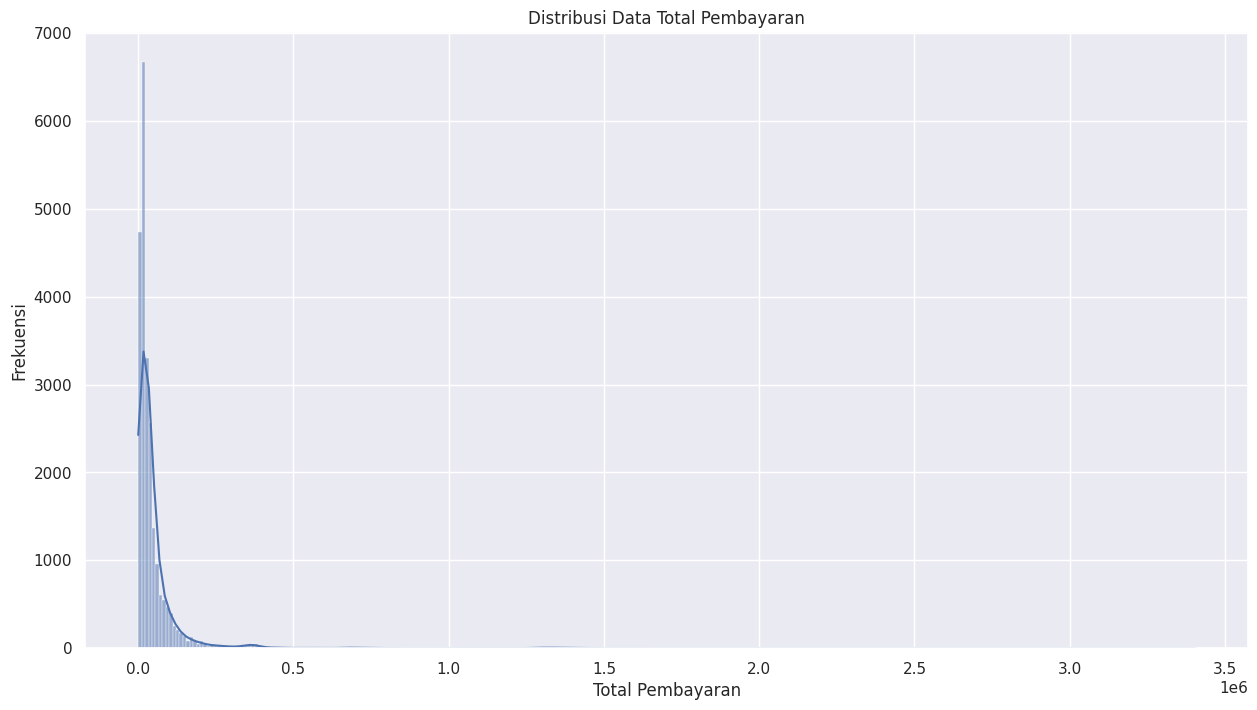

In [40]:
# Distribusi Data Total Pembayaran

plt.figure(figsize=(15, 8))
plt.title('Distribusi Data Total Pembayaran')
sns.histplot(df['Total Pembayaran'], kde=True)
plt.xlabel('Total Pembayaran')
plt.ylabel('Frekuensi')
plt.show()

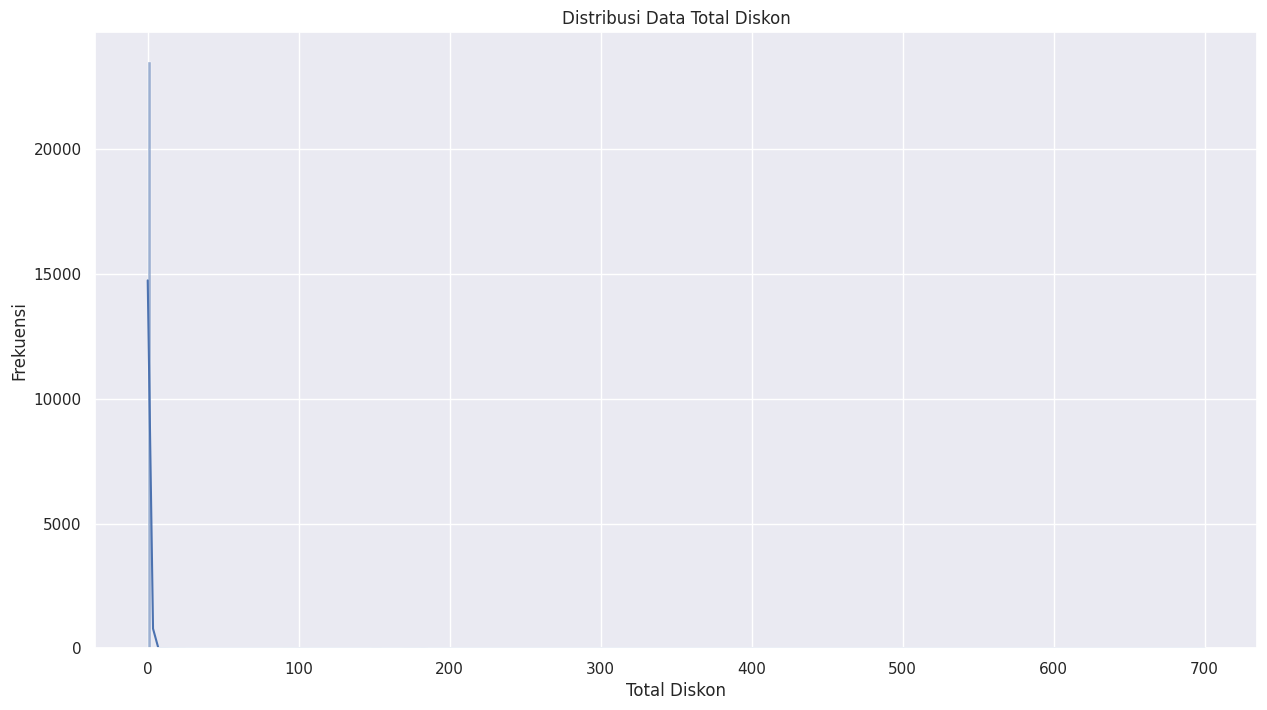

In [41]:
# Distribusi Data Total Diskon

plt.figure(figsize=(15, 8))
plt.title('Distribusi Data Total Diskon')
sns.histplot(df['Total Diskon'], kde=True)
plt.xlabel('Total Diskon')
plt.ylabel('Frekuensi')
plt.show()

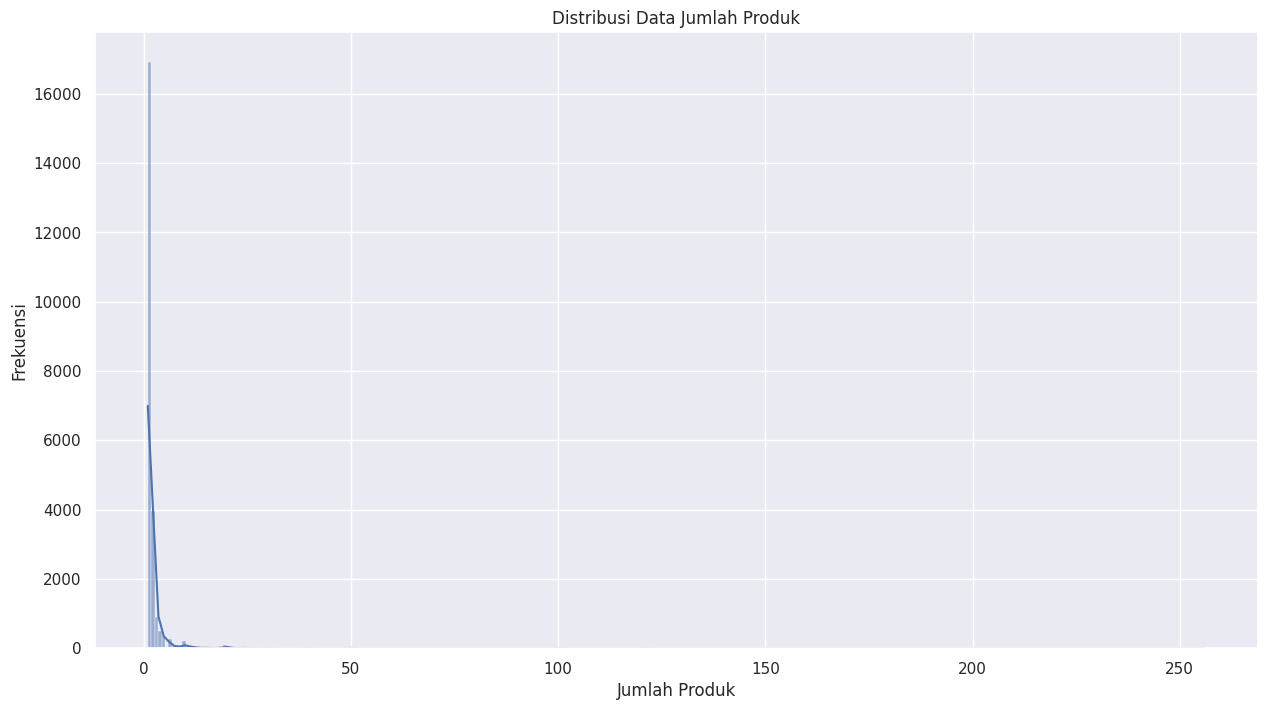

In [42]:
# Distribusi Data Jumlah Produk

plt.figure(figsize=(15, 8))
plt.title('Distribusi Data Jumlah Produk')
sns.histplot(df['Jumlah'], kde=True)
plt.xlabel('Jumlah Produk')
plt.ylabel('Frekuensi')
plt.show()

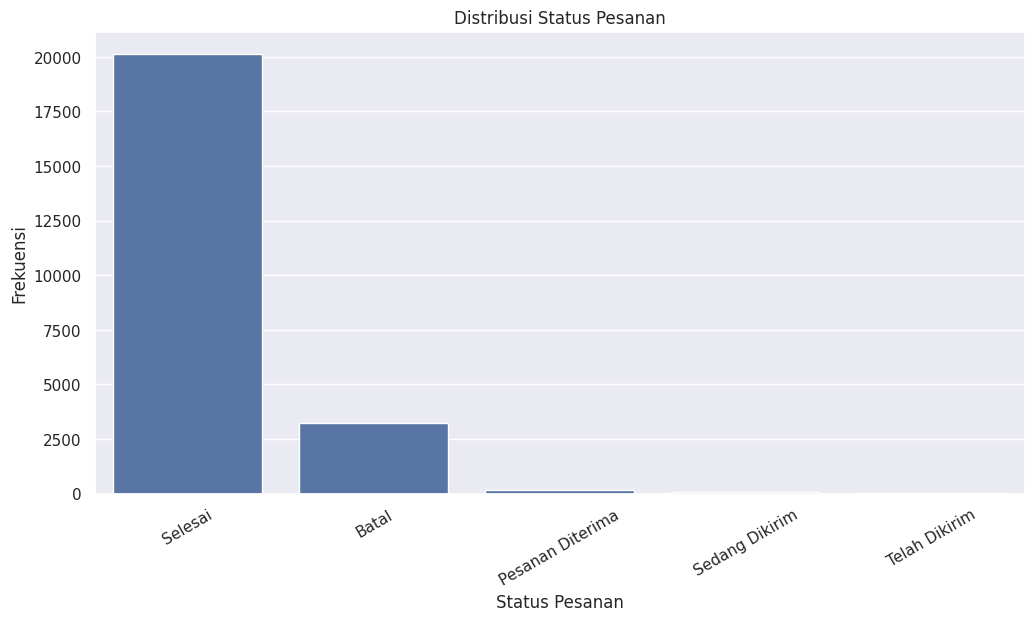

In [43]:
# Distribusi Status Pesanan

plt.figure(figsize=(12, 6))
plt.title('Distribusi Status Pesanan')
sns.countplot(data=df, x='Status Pesanan Ringkas')
plt.xlabel('Status Pesanan')
plt.ylabel('Frekuensi')
plt.xticks(rotation=30)
plt.show()

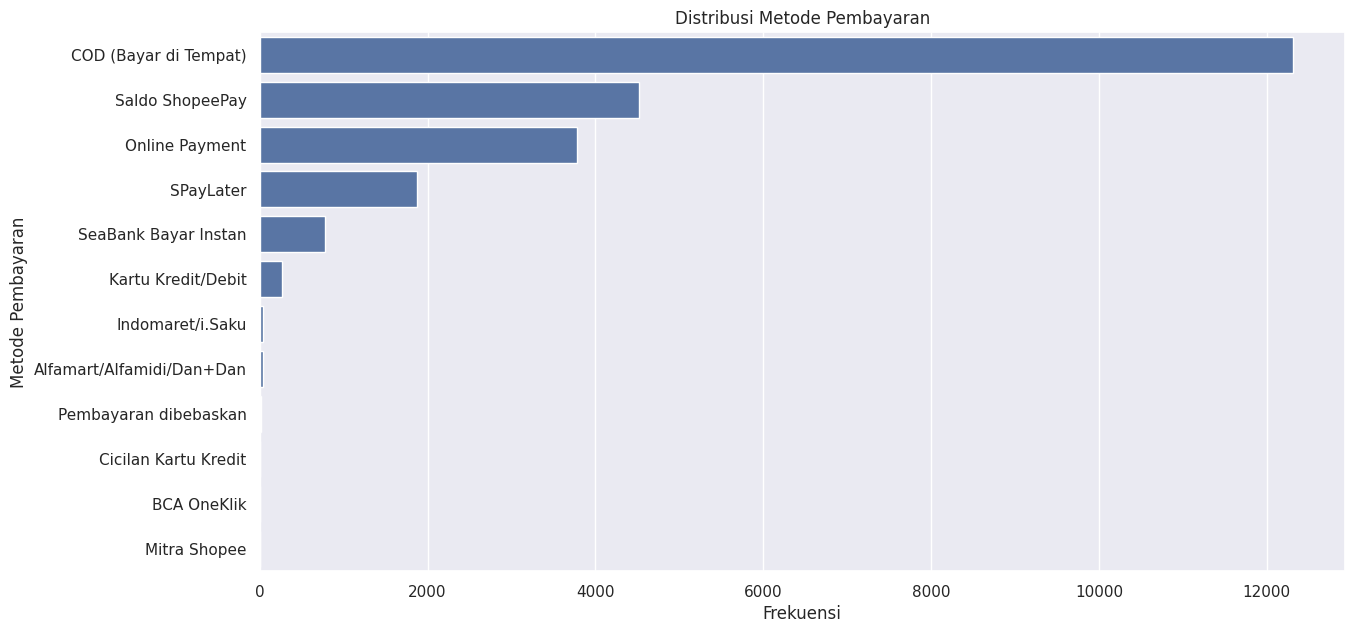

In [44]:
# Distribusi Metode Pembayaran

plt.figure(figsize=(14, 7))
plt.title('Distribusi Metode Pembayaran')
sns.countplot(
    data=df,
    y='Metode Pembayaran',
    order=df['Metode Pembayaran'].value_counts().index
)
plt.xlabel('Frekuensi')
plt.ylabel('Metode Pembayaran')
plt.show()

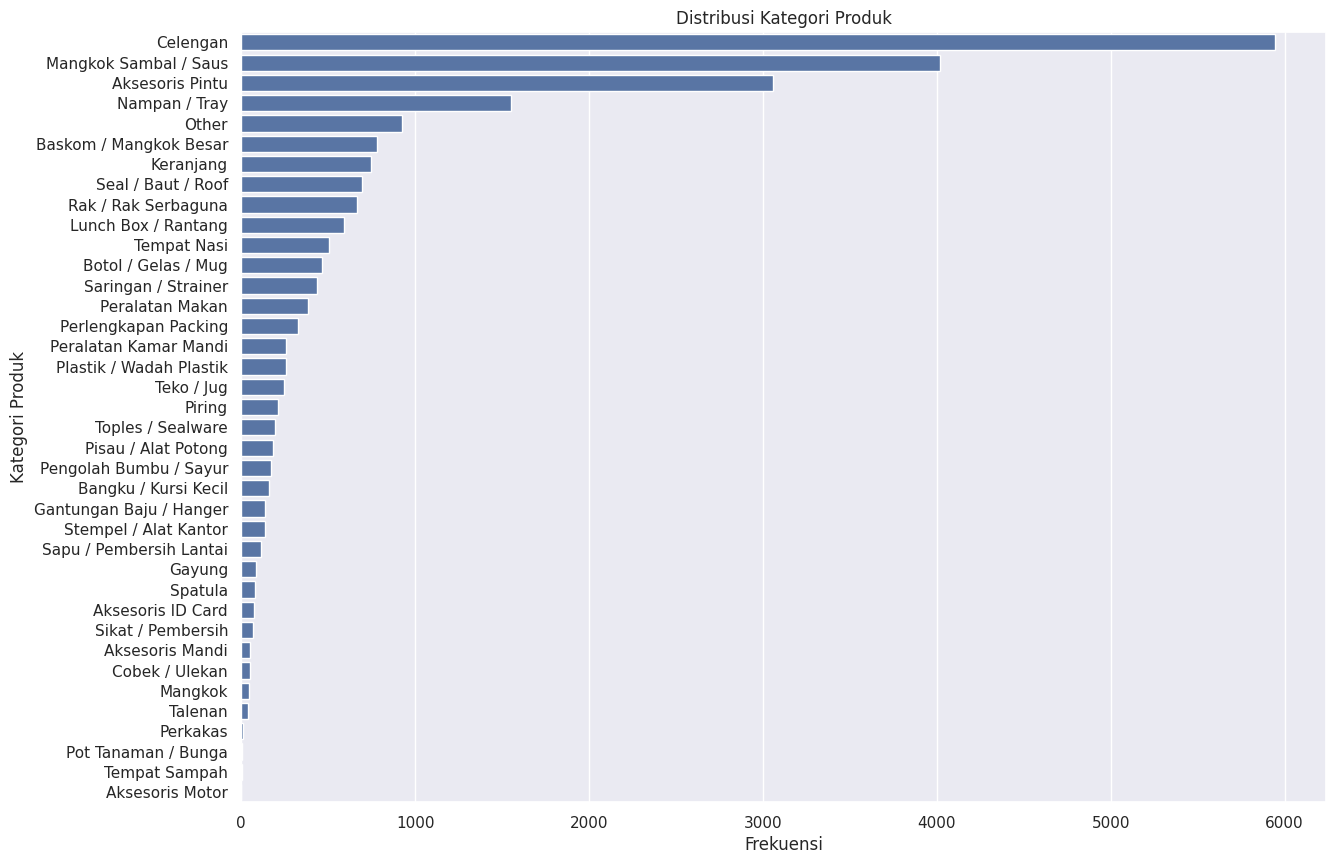

In [45]:
# Distribusi Kategori Produk

plt.figure(figsize=(14, 10))
plt.title('Distribusi Kategori Produk')
sns.countplot(
    data=df,
    y='product_category',
    order=df['product_category'].value_counts().index
)
plt.xlabel('Frekuensi')
plt.ylabel('Kategori Produk')
plt.show()

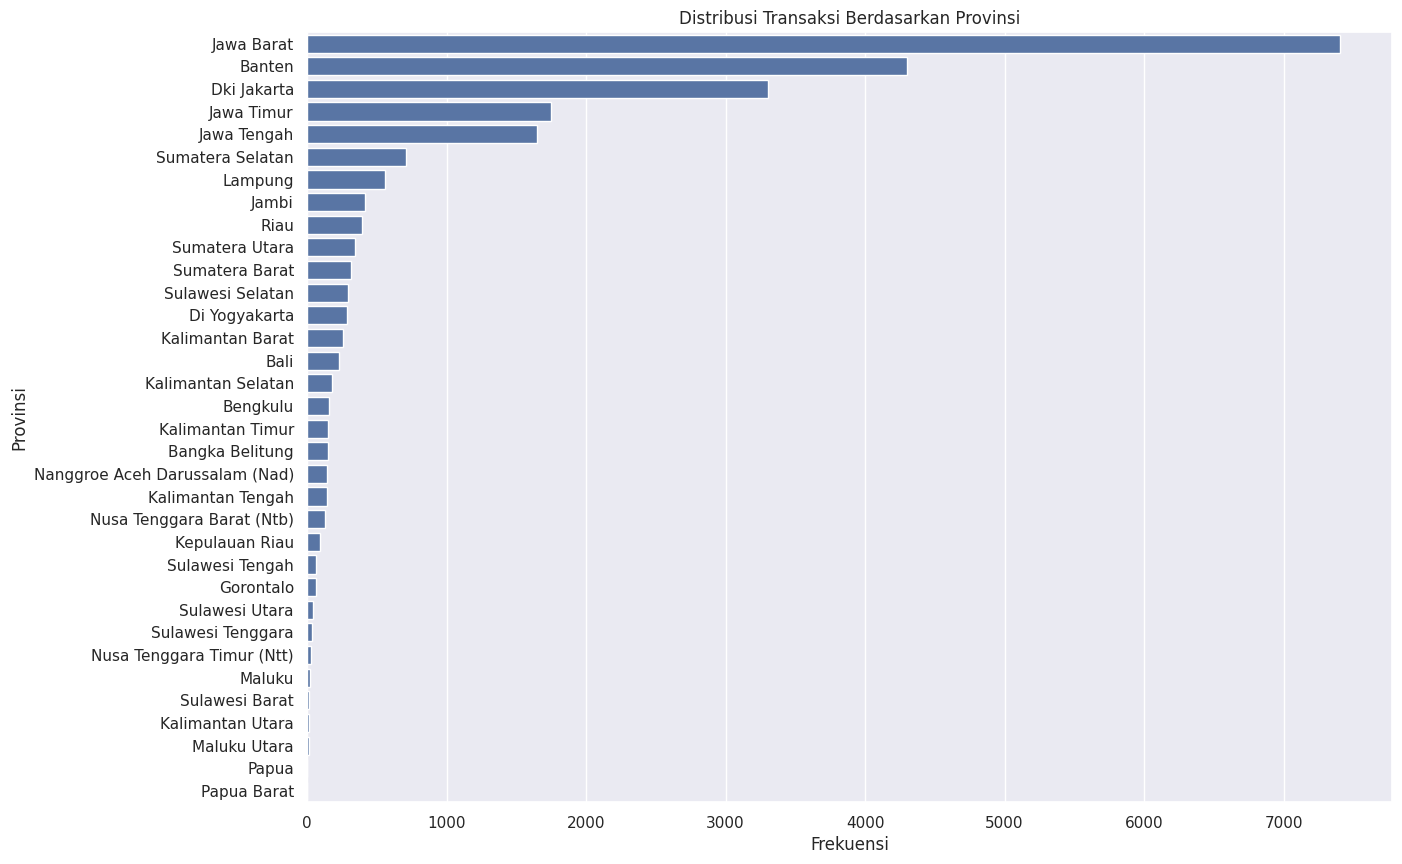

In [46]:
# Distribusi Transaksi Berdasarkan Provinsi

plt.figure(figsize=(14, 10))
plt.title('Distribusi Transaksi Berdasarkan Provinsi')
sns.countplot(
    data=df,
    y='Provinsi',
    order=df['Provinsi'].value_counts().index
)
plt.xlabel('Frekuensi')
plt.ylabel('Provinsi')
plt.show()

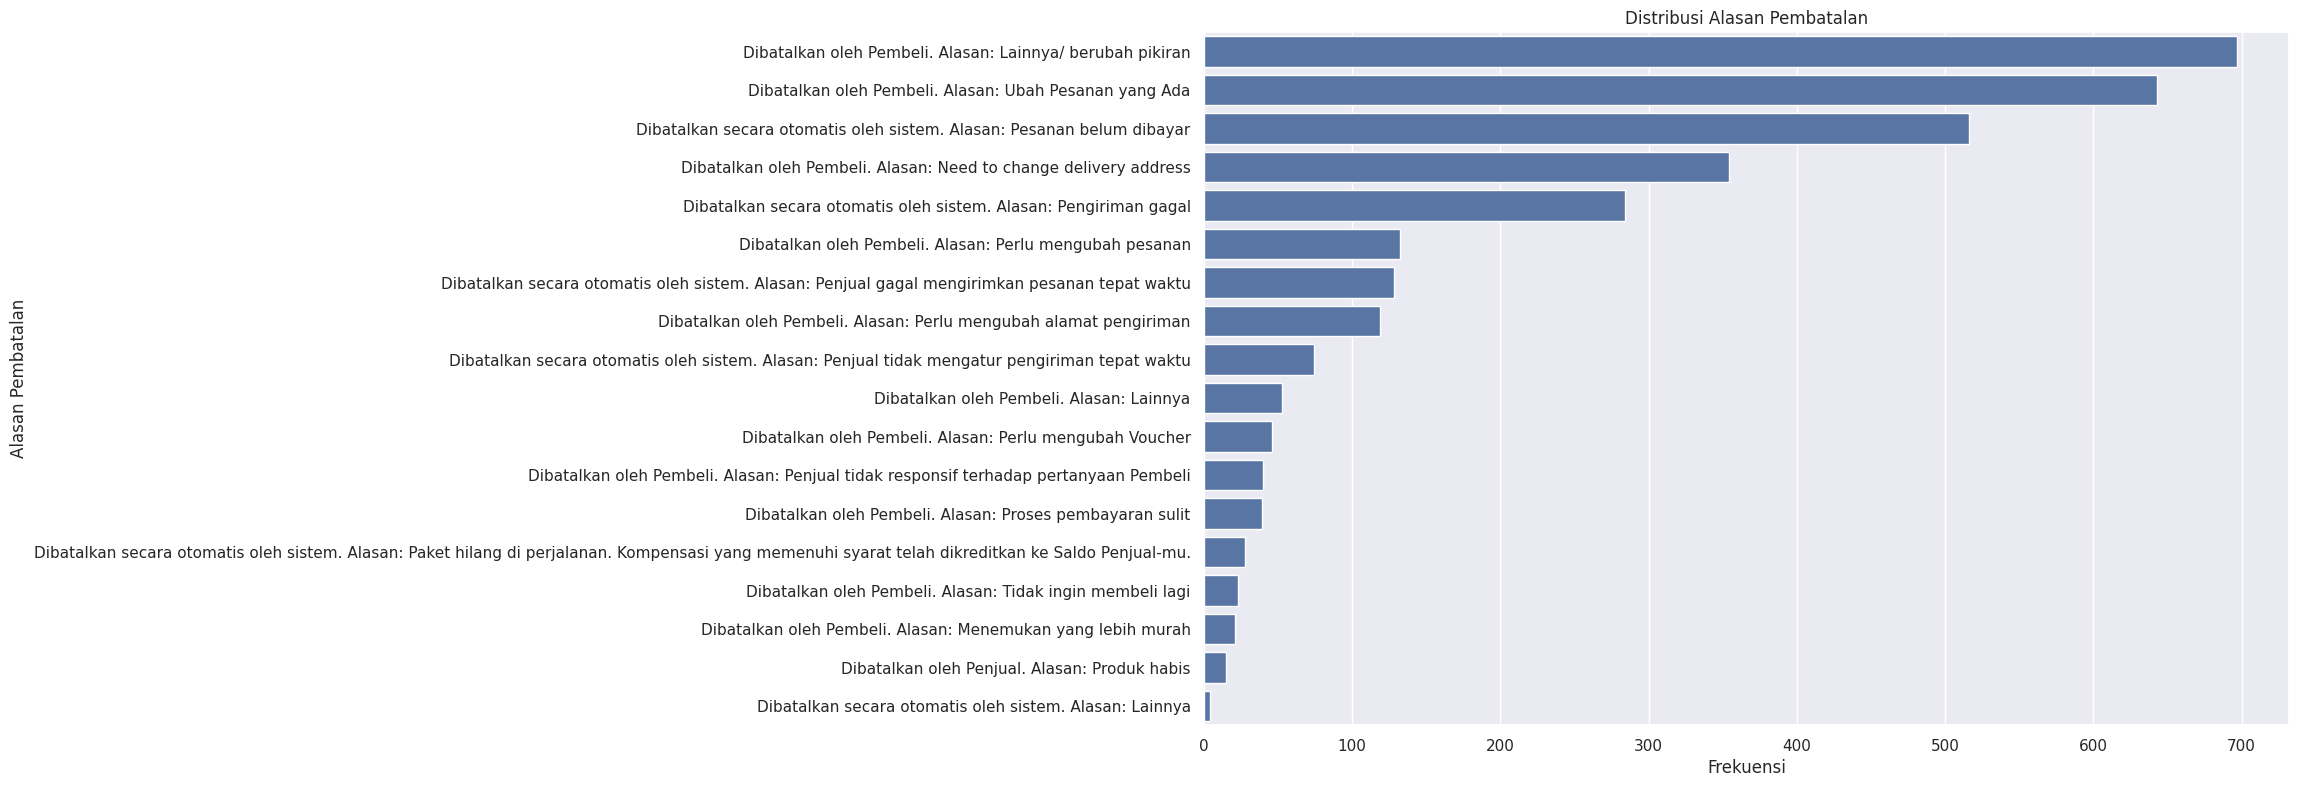

In [47]:
# Distribusi Alasan Pembatalan

plt.figure(figsize=(14, 9))
plt.title('Distribusi Alasan Pembatalan')

sns.countplot(
    data=df.dropna(subset=['Alasan Pembatalan']),
    y='Alasan Pembatalan',
    order=df['Alasan Pembatalan'].value_counts().index
)

plt.xlabel('Frekuensi')
plt.ylabel('Alasan Pembatalan')
plt.show()

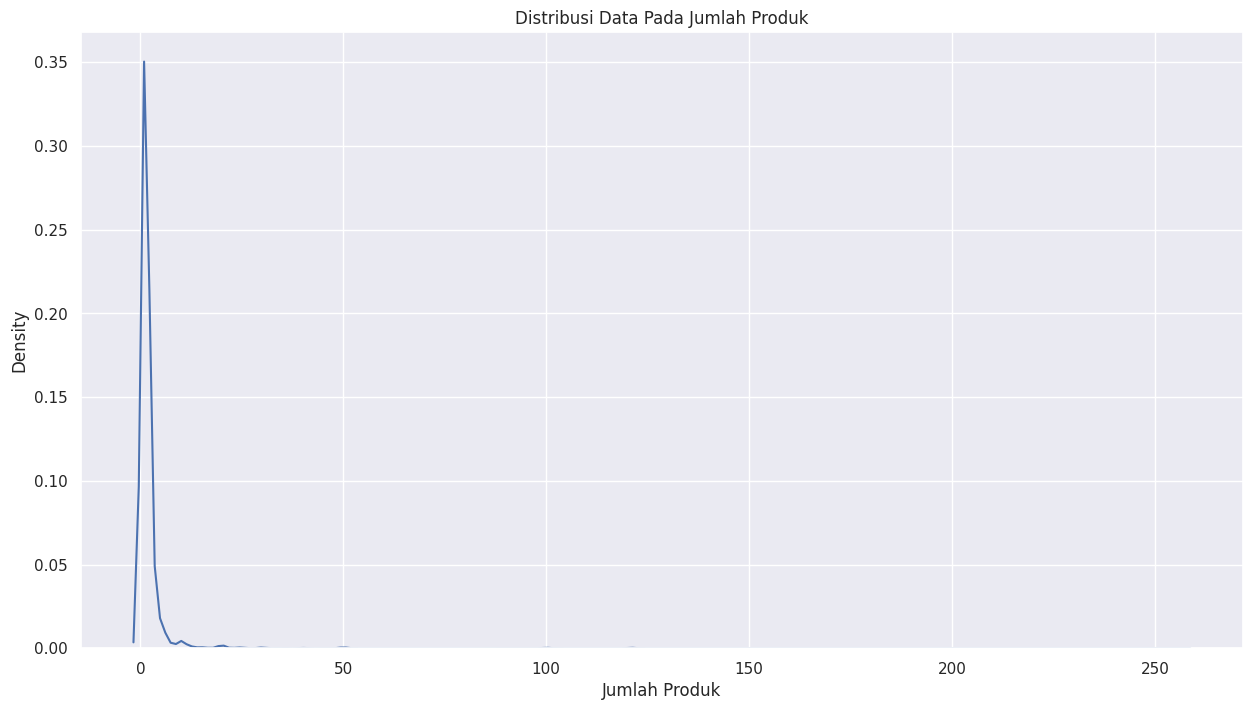

In [48]:
# Distribusi Data Jumlah Produk

plt.figure(figsize=(15, 8))
plt.title('Distribusi Data Pada Jumlah Produk')
sns.kdeplot(df['Jumlah'])
plt.xlabel('Jumlah Produk')
plt.show()

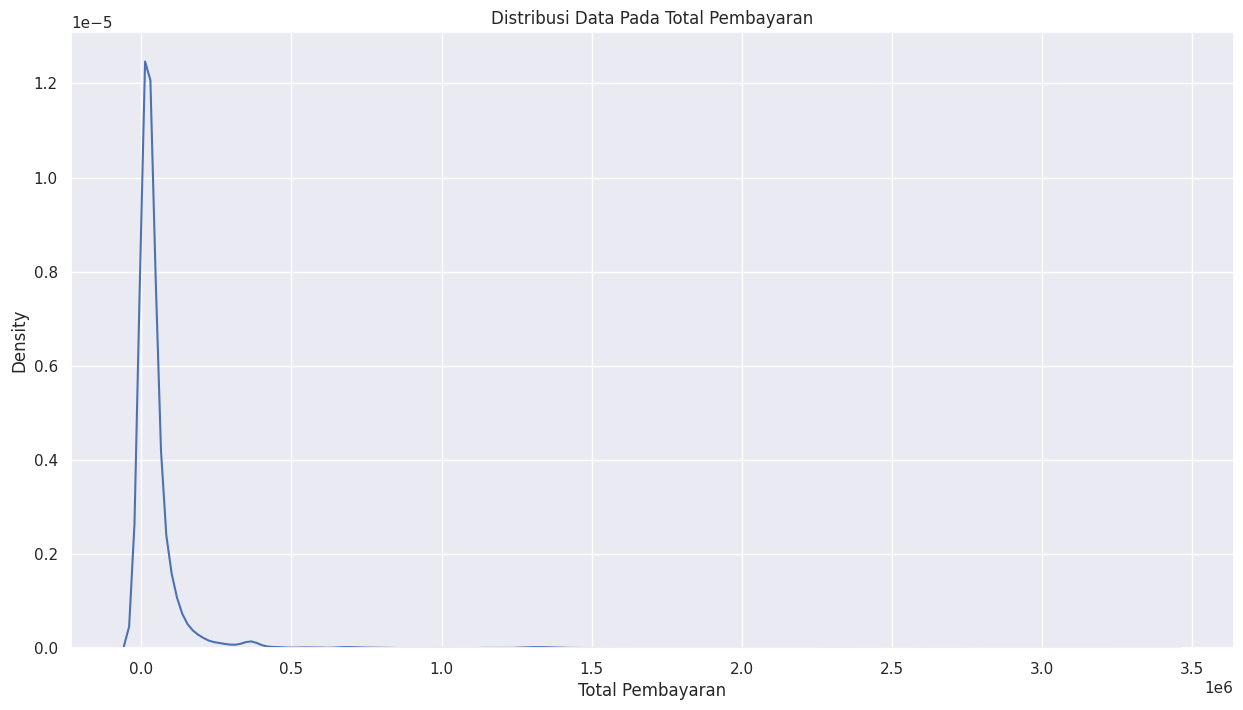

In [49]:
# Distribusi Data Total Pembayaran

plt.figure(figsize=(15, 8))
plt.title('Distribusi Data Pada Total Pembayaran')
sns.kdeplot(df['Total Pembayaran'])
plt.xlabel('Total Pembayaran')
plt.show()

Catatan :
- Analisis univariat digunakan untuk melihat distribusi masing-masing variabel.
- Distribusi Total Pembayaran, Total Diskon, dan Jumlah Produk menunjukkan konsentrasi data pada nilai yang relatif rendah serta beberapa nilai yang jauh lebih tinggi.
- Kategori produk, provinsi, metode pembayaran, status pesanan, dan alasan pembatalan memiliki frekuensi yang bervariasi.
- Frekuensi pada grafik univariat dihitung berdasarkan baris data setelah penghapusan duplikasi penuh, bukan selalu berdasarkan jumlah pesanan unik.

## (6.3) Bivariate Analysis

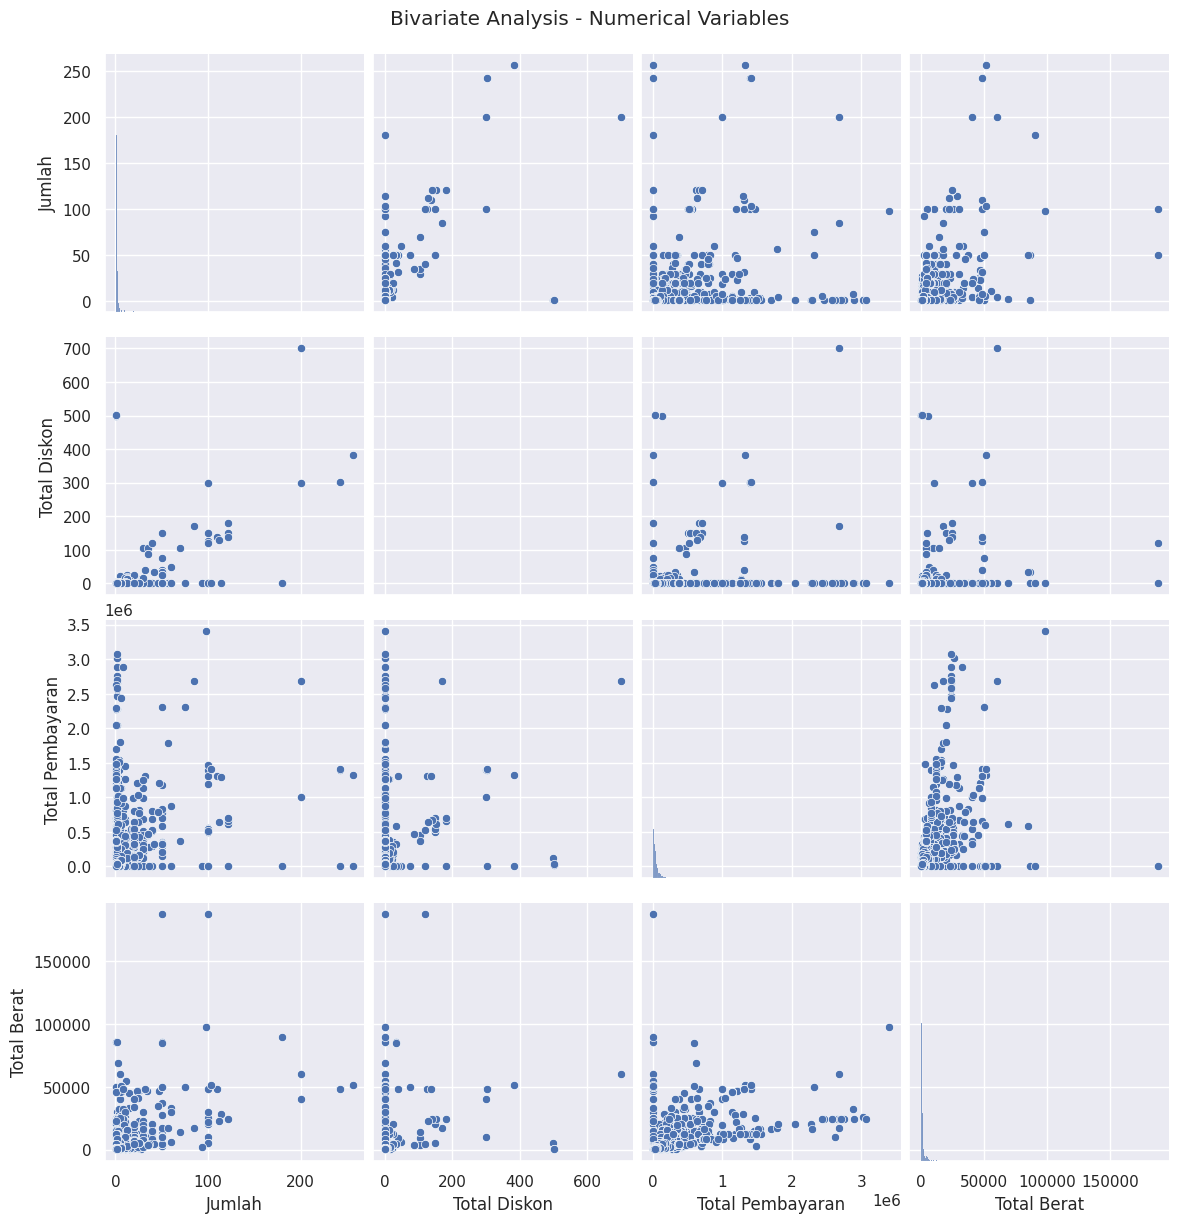

In [50]:
# Melakukan Bivariate Analysis pada data bertipe numerik

numeric_cols = [
    'Jumlah',
    'Total Diskon',
    'Total Pembayaran',
    'Total Berat'
]

g = sns.pairplot(df[numeric_cols], kind='scatter', height=3)
g.fig.suptitle('Bivariate Analysis - Numerical Variables', y=1.02)
plt.show()

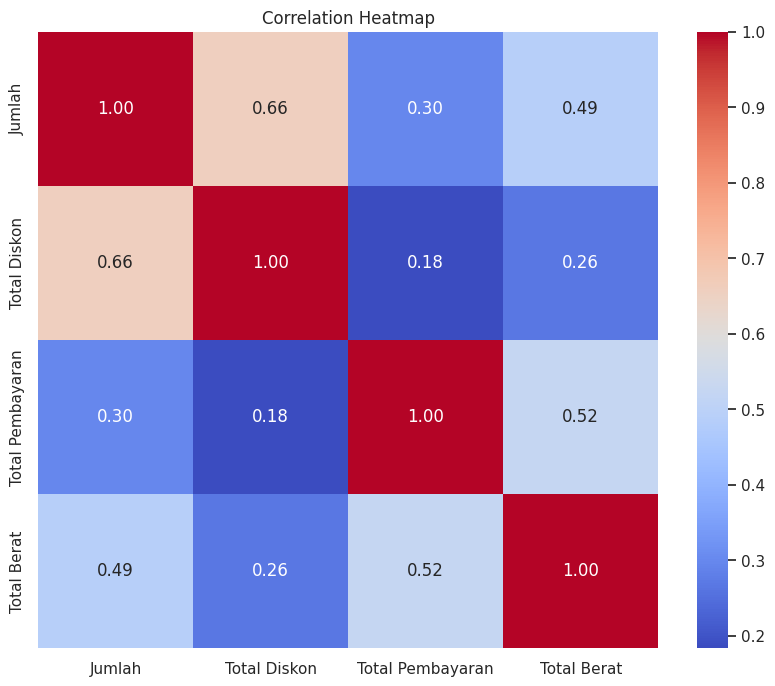

In [51]:
# Melihat Korelasi Antarvariabel Numerik

plt.figure(figsize=(10, 8))

sns.heatmap(
    df[['Jumlah', 'Total Diskon', 'Total Pembayaran', 'Total Berat']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

Catatan :
- Pairplot dan heatmap digunakan untuk mengamati pola hubungan antarvariabel numerik.
- Hasil korelasi menunjukkan hubungan antarvariabel memiliki kekuatan yang berbeda.
- Korelasi hanya menunjukkan hubungan statistik dan tidak membuktikan hubungan sebab-akibat.
- Nilai pembayaran merupakan nilai pada tingkat pesanan yang dapat muncul pada beberapa baris kategori dalam satu pesanan. Oleh karena itu, analisis yang menggunakan total pembayaran dilakukan dengan satu baris per `order_id`.

# (7) Analysis Process

## (7.1) Kategori Produk dengan Jumlah Pesanan Terbanyak

In [52]:
# Kategori Produk dengan Jumlah Pesanan Terbanyak

df1 = df.groupby(['product_category'])['order_id'].nunique().to_frame()
df1 = df1.sort_values('order_id', ascending=False)
df1.rename(columns={'order_id': 'Jumlah Pesanan'}, inplace=True)
df1.reset_index(inplace=True)
df1.index += 1

topCategory = df1.head(10)
topCategory

,product_category,Jumlah Pesanan
1,Celengan,5869
2,Mangkok Sambal / Saus,3952
3,Aksesoris Pintu,2962
4,Nampan / Tray,1514
5,Other,898
6,Baskom / Mangkok Besar,760
7,Keranjang,718
8,Seal / Baut / Roof,690
9,Rak / Rak Serbaguna,663
10,Lunch Box / Rantang,569


## (7.2) Tren Total Pembayaran Berdasarkan Bulan

In [53]:
# Menggunakan satu baris untuk setiap order_id agar pembayaran tidak dihitung berulang

df2 = df.drop_duplicates(subset='order_id').copy()

df2['Bulan'] = df2['Tanggal Analisis'].dt.to_period('M')

df2 = df2.groupby('Bulan')['Total Pembayaran'].sum().to_frame()
df2.reset_index(inplace=True)

# Mengubah period menjadi datetime agar dapat divisualisasikan
df2['Bulan'] = df2['Bulan'].dt.to_timestamp()

df2

,Bulan,Total Pembayaran
0,2023-12-01,23850125.0
1,2024-01-01,24492481.0
2,2024-02-01,21141376.0
3,2024-03-01,30259734.0
4,2024-04-01,21260662.0
5,2024-05-01,35530574.0
6,2024-06-01,32465925.0
7,2024-07-01,63791545.0
8,2024-08-01,65939126.0
9,2024-09-01,71193097.0


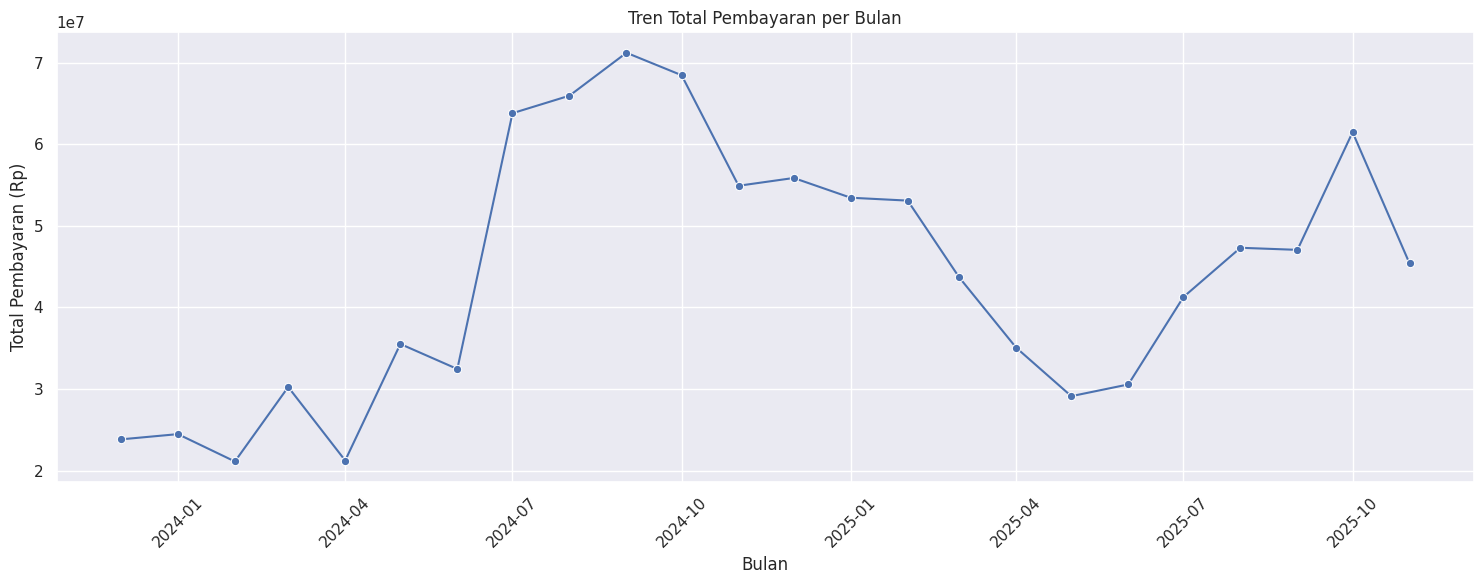

In [54]:
plt.figure(figsize=(15, 6))

sns.lineplot(
    data=df2,
    x='Bulan',
    y='Total Pembayaran',
    marker='o'
)

plt.title('Tren Total Pembayaran per Bulan')
plt.xlabel('Bulan')
plt.ylabel('Total Pembayaran (Rp)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

## (7.3) Provinsi dengan Total Pembayaran Tertinggi

In [55]:
# Provinsi dengan Total Pembayaran Tertinggi

df3 = df.drop_duplicates(subset='order_id').copy()

df3 = df3.groupby(['Provinsi'])['Total Pembayaran'].sum().to_frame()
df3 = df3.sort_values('Total Pembayaran', ascending=False)
df3.rename(columns={'Total Pembayaran': 'Total Penjualan'}, inplace=True)
df3.reset_index(inplace=True)
df3.index += 1

topProvince = df3.head(10)
topProvince

,Provinsi,Total Penjualan
1,Jawa Barat,276992073.0
2,Banten,177861752.0
3,Dki Jakarta,135164841.0
4,Jawa Tengah,100114044.0
5,Jawa Timur,95478924.0
6,Sumatera Selatan,40909428.0
7,Lampung,22028652.0
8,Bali,21951090.0
9,Sumatera Utara,19783218.0
10,Sulawesi Selatan,19680129.0


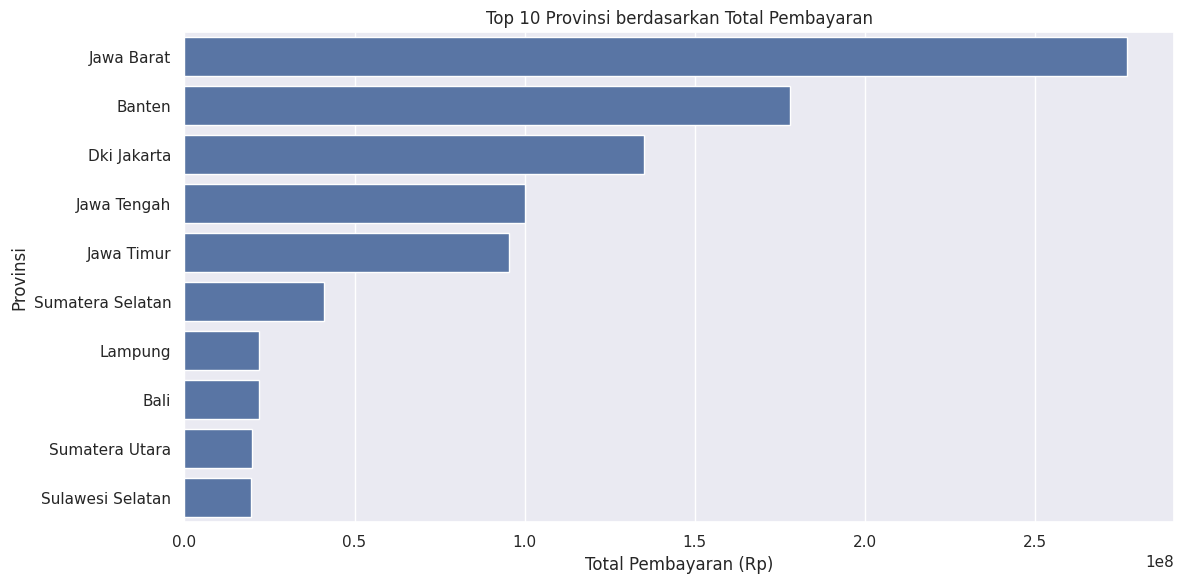

In [56]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=topProvince,
    x='Total Penjualan',
    y='Provinsi'
)

plt.title('Top 10 Provinsi berdasarkan Total Pembayaran')
plt.xlabel('Total Pembayaran (Rp)')
plt.ylabel('Provinsi')
plt.tight_layout()
plt.show()

## (7.4) Hubungan Total Diskon dan Total Pembayaran

In [57]:
# Analisis Hubungan Total Diskon dan Total Pembayaran

df4 = df.drop_duplicates(subset='order_id').copy()

df4[['Total Diskon', 'Total Pembayaran']].corr()

,Total Diskon,Total Pembayaran
Total Diskon,1.000000,0.210377
Total Pembayaran,0.210377,1.000000


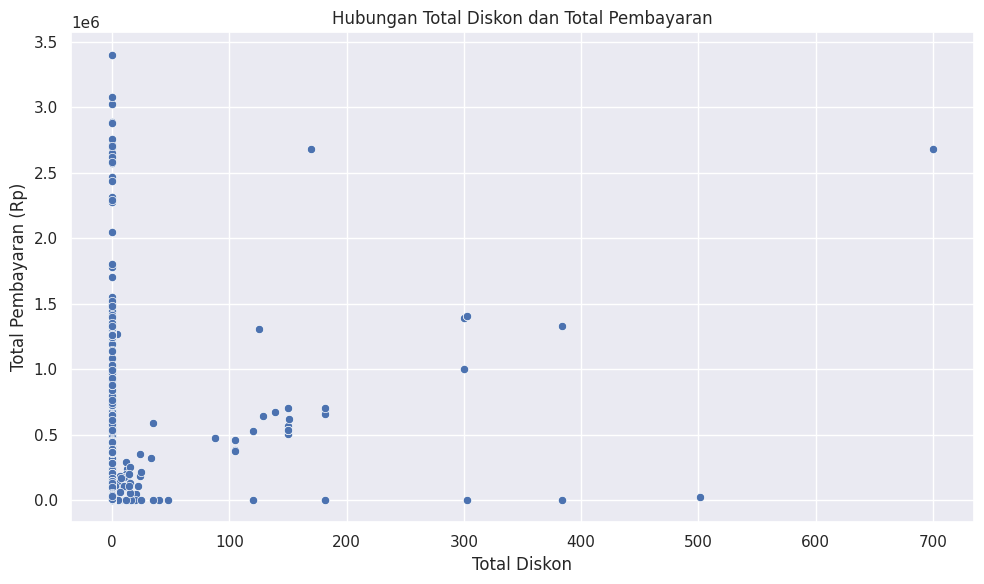

In [58]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df4,
    x='Total Diskon',
    y='Total Pembayaran'
)

plt.title('Hubungan Total Diskon dan Total Pembayaran')
plt.xlabel('Total Diskon')
plt.ylabel('Total Pembayaran (Rp)')
plt.tight_layout()
plt.show()

## (7.5) Metode Pembayaran yang Paling Banyak Digunakan

In [59]:
# Metode Pembayaran yang Paling Banyak Digunakan

df5 = df.drop_duplicates(subset='order_id').copy()

df5 = df5.groupby(['Metode Pembayaran'])['order_id'].nunique().to_frame()
df5 = df5.sort_values('order_id', ascending=False)
df5.rename(columns={'order_id': 'Jumlah Pesanan'}, inplace=True)
df5.reset_index(inplace=True)
df5.index += 1

df5

,Metode Pembayaran,Jumlah Pesanan
1,COD (Bayar di Tempat),11538
2,Saldo ShopeePay,3692
3,Online Payment,3170
4,SPayLater,1485
5,SeaBank Bayar Instan,637
6,Kartu Kredit/Debit,222
7,Indomaret/i.Saku,43
8,Alfamart/Alfamidi/Dan+Dan,36
9,Pembayaran dibebaskan,18
10,BCA OneKlik,3


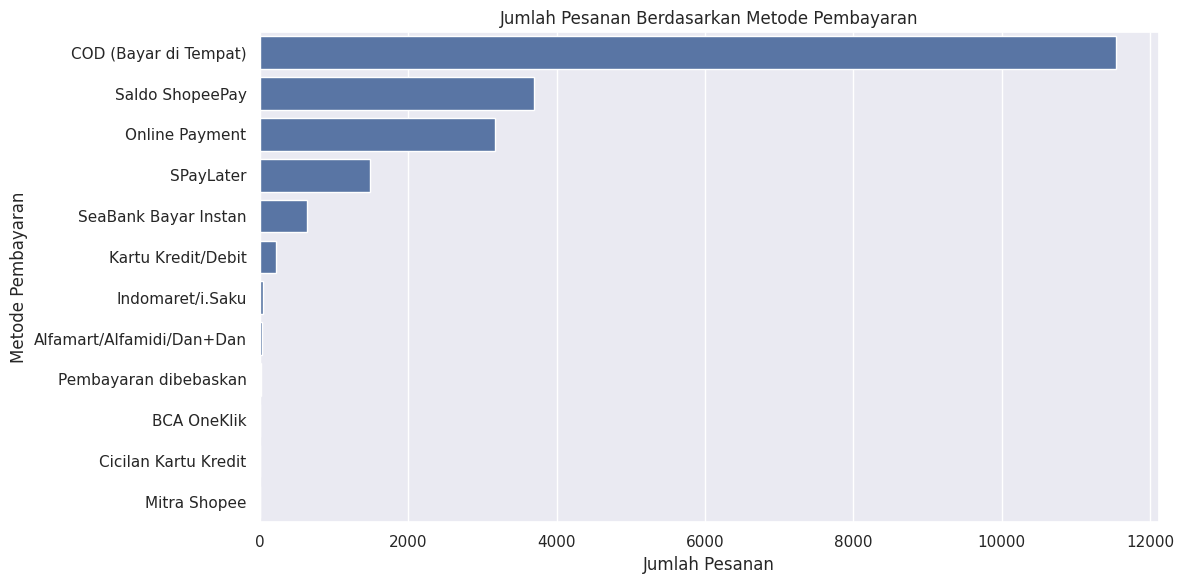

In [60]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df5,
    x='Jumlah Pesanan',
    y='Metode Pembayaran'
)

plt.title('Jumlah Pesanan Berdasarkan Metode Pembayaran')
plt.xlabel('Jumlah Pesanan')
plt.ylabel('Metode Pembayaran')
plt.tight_layout()
plt.show()

## (7.6) Jumlah Pesanan Berdasarkan Pihak Pembatalan

In [61]:
# Jumlah Pesanan Berdasarkan Pihak Pembatalan

df6 = df.drop_duplicates(subset='order_id').copy()

df6 = df6.groupby(['Pihak Pembatalan'])['order_id'].nunique().to_frame()
df6 = df6.sort_values('order_id', ascending=False)
df6.rename(columns={'order_id': 'Jumlah Pesanan'}, inplace=True)
df6.reset_index(inplace=True)
df6.index += 1

df6

,Pihak Pembatalan,Jumlah Pesanan
1,Pembeli,1912
2,sistem,904
3,Penjual,14


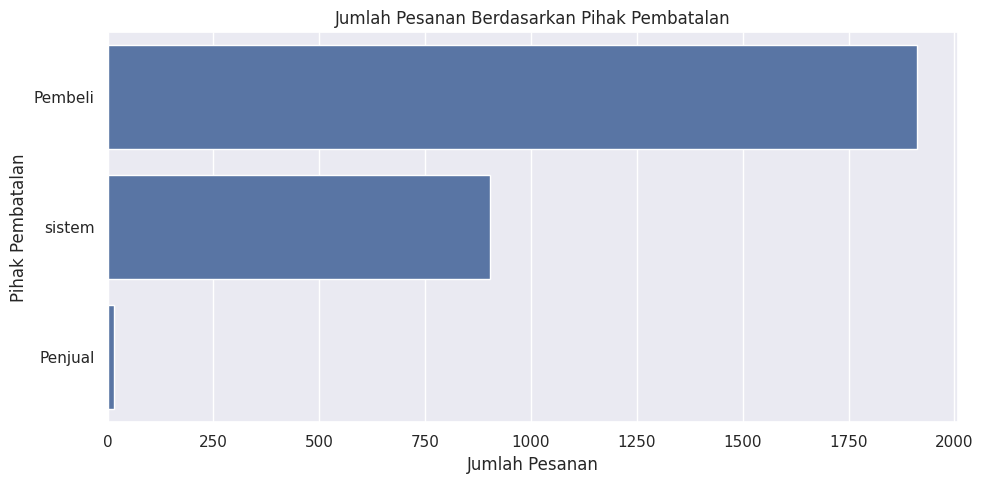

In [62]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df6,
    x='Jumlah Pesanan',
    y='Pihak Pembatalan'
)

plt.title('Jumlah Pesanan Berdasarkan Pihak Pembatalan')
plt.xlabel('Jumlah Pesanan')
plt.ylabel('Pihak Pembatalan')
plt.tight_layout()
plt.show()

# (8) Insight and Information based on Analysis Result

**Kesimpulan :**

- Berdasarkan hasil analisis tren total pembayaran E-Commerce selama periode Desember 2023 hingga November 2025, diperoleh beberapa temuan:
  - **September 2024** merupakan bulan dengan total pembayaran tertinggi sebesar **Rp71.193.097**.
  - **Mei 2025** merupakan bulan dengan total pembayaran terendah sebesar **Rp29.139.406**.
  - Setelah mengalami penurunan hingga Mei 2025, total pembayaran kembali meningkat dan mencapai **Rp61.464.654** pada Oktober 2025.

- Berdasarkan kategori produk dengan jumlah pesanan terbanyak, terdapat 10 kategori produk dengan jumlah pesanan tertinggi, yaitu:
  1. **Celengan** dengan 5.869 pesanan (Top 1).
  2. **Mangkok Sambal / Saus** dengan 3.952 pesanan (Top 2).
  3. **Aksesoris Pintu** dengan 2.962 pesanan (Top 3).
  4. **Nampan / Tray** dengan 1.514 pesanan.
  5. **Other** dengan 898 pesanan.
  6. **Baskom / Mangkok Besar** dengan 760 pesanan.
  7. **Keranjang** dengan 718 pesanan.
  8. **Seal / Baut / Roof** dengan 690 pesanan.
  9. **Rak / Rak Serbaguna** dengan 663 pesanan.
  10. **Lunch Box / Rantang** dengan 569 pesanan.

- Berdasarkan wilayah atau provinsi dengan total pembayaran tertinggi, diperoleh 10 provinsi dengan nilai transaksi terbesar, yaitu:
  1. **Jawa Barat** sebesar Rp276.992.073 (Top 1).
  2. **Banten** sebesar Rp177.861.752 (Top 2).
  3. **DKI Jakarta** sebesar Rp135.164.841 (Top 3).
  4. **Jawa Tengah** sebesar Rp100.114.044.
  5. **Jawa Timur** sebesar Rp95.478.924.
  6. **Sumatera Selatan** sebesar Rp40.909.428.
  7. **Lampung** sebesar Rp22.028.652.
  8. **Bali** sebesar Rp21.951.090.
  9. **Sumatera Utara** sebesar Rp19.783.218.
  10. **Sulawesi Selatan** sebesar Rp19.680.129.

- Berdasarkan analisis diskon, metode pembayaran, dan pembatalan pesanan, terdapat beberapa temuan:
  - Hubungan antara **Total Diskon dan Total Pembayaran** memiliki korelasi positif lemah sebesar **0,210377**.
  - Metode pembayaran yang paling banyak digunakan adalah **COD (Bayar di Tempat)** dengan 11.538 pesanan, diikuti Saldo ShopeePay sebanyak 3.692 pesanan dan Online Payment sebanyak 3.170 pesanan.
  - Berdasarkan pihak pembatalan, **Pembeli** menjadi pihak dengan jumlah pembatalan tertinggi sebanyak 1.912 pesanan, diikuti sistem sebanyak 904 pesanan dan Penjual sebanyak 14 pesanan.

- Berdasarkan hasil analisis data E-Commerce tersebut, terdapat beberapa insight dan rekomendasi yang dapat dijadikan sebagai

## (9) Exporting Data

In [ ]:
with pd.ExcelWriter('Ecommerce_Sales_Analysis.xlsx') as writer:
    df.to_excel(writer, sheet_name='Original', index=False)
    topCategory.to_excel(writer, sheet_name='Top Category', index=False)
    df2.to_excel(writer, sheet_name='Monthly Payment', index=False)
    topProvince.to_excel(writer, sheet_name='Top Province', index=False)
    df5.to_excel(writer, sheet_name='Payment Method', index=False)
    df6.to_excel(writer, sheet_name='Cancellation', index=False)